In [1]:
import numpy as np
from isochrones.mist import MIST_Isochrone

PyMultiNest not imported.  MultiNest fits will not work.


In [31]:
feh=-2.5
age_gyr = 12

mist = MIST_Isochrone(bands=['PS_g', 'PS_r'])
log_age = np.log10(age_gyr * 1e9)

In [ ]:
df = mist.isochrone(log_age, feh, dropna=True)  # age=12 Gyr, metallicity=-2.5

In [13]:
mass_col = "initial_mass" if "initial_mass" in df.columns else "mass"
order = np.argsort(df[mass_col].to_numpy())

In [18]:
initial_mass = df[mass_col].to_numpy()[order]

In [19]:
def _col(band: str) -> np.ndarray:
    name = band if band in df.columns else f"{band}_mag"
    return df[name].to_numpy()[order]


In [20]:
abs_g0 = _col("PS_g")
abs_r0 = _col("PS_r")

In [ ]:
d = np.diff(abs_g0)
turnover = np.flatnonzero(d >= 0)
stop = (turnover[0] + 1) if turnover.size else len(abs_g0)

In [22]:
stop

np.int64(353)

In [23]:
turnover

array([352, 353, 354, 355, 356, 357, 358, 362, 364, 365, 366, 368, 370,
       373, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 387, 391,
       392, 393, 394, 398, 399, 400, 414, 415, 423, 424, 431, 432, 436,
       439, 440, 443, 444, 445, 464, 465, 467])

In [25]:
mass_r = initial_mass[:stop]
abs_g_r = abs_g0[:stop]
abs_r_r = abs_r0[:stop]

In [26]:
print(
    f"  -> restricted to {len(mass_r)} monotonic (MS/turnoff/subgiant) points, "
    f"abs g in [{abs_g_r.min():.2f}, {abs_g_r.max():.2f}]"
)

  -> restricted to 353 monotonic (MS/turnoff/subgiant) points, abs g in [-2.06, 13.08]


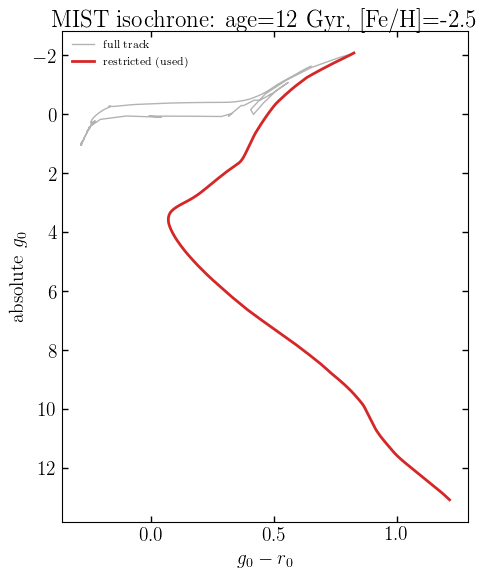

In [34]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(abs_g0-abs_r0, abs_g0, color="0.7", lw=1, label="full track")
ax.plot(abs_g_r-abs_r_r, abs_g_r, color="tab:red", lw=2, label="restricted (used)")
ax.invert_yaxis()
ax.set_xlabel(r"$g_0-r_0$")
ax.set_ylabel(r"absolute $g_0$")
ax.set_title(f"MIST isochrone: age={age_gyr} Gyr, [Fe/H]={feh}")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
plt.show()